In [8]:
dna_sequence = (
    "AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTCTGATAGCAGC"
    "TTCTGAACTGGTTACCTGCCGTGAGTAAATTAAAATTTTATTGACTTAGGTCACTAAATACTTTAACCAA"
    "TATAGGCATAGCGCACAGACAGATAAAAATTACAGAGTACACAACATCCATGAAACGCATTAGCACCACC"
    "ATTACCACCACCATCACCATTACCACAGGTAACGGTGCGGGCTGACGCGTACAGGAAACACAGAAAAAAG"
    "CCCGCACCTGACAGTGCGGGCTTTTTTTTTCGACCAAAGGTAACGAGGTAACAACCATGCGAGTGTTGAA"
    "GTTCGGCGGTACATCAGTGGCAAATGCAGAACGTTTTCTGCGTGTTGCCGATATTCTGGAAAGCAATGCC"
    "AGGCAGGGGCAGGTGGCCACCGTCCTCTCTGCCCCCGCCAAAATCACCAACCACCTGGTGGCGATGATTG"
    "AAAAAACCATTAGCGGCCAGGATGCTTTACCCAATATCAGCGATGCCGAACGTATTTTTGCCGAACTTTT"
    "GACGGGACTCGCCGCCGCCCAGCCGGGGTTCCCGCTGGCGCAATTGAAAACTTTCGTCGATCAGGAATTT"
    "GCCCAAATAAAACATGTCCTGCATGGCATTAGTTTGTTGGGGCAGTGCCCGGATAGCATCAACGCTGCGC"
    "TGATTTGCCGTGGCGAGAAAATGTCGATCGCCATTATGGCCGGCGTATTAGAAGCGCGCGGTCACAACGT"
    "TACTGTTATCGATCCGGTCGAAAAACTGCTGGCAGTGGGGCATTACCTCGAATCTACCGTCGATATTGCT"
    "GAGTCCACCCGCCGTATTGCGGCAAGCCGCATTCCGGCTGATCACATGGTGCTGATGGCAGGTTTCACCG"
    "CCGGTAATGAAAAAGGCGAACTGGTGGTGCTTGGACGCAACGGTTCCGACTACTCTGCTGCGGTGCTGGC"
    "TGCCTGTTTACGCGCCGATTGTTGCGAGATTTGGACGGACGTTGACGGGGTCTATACCTGCGACCCGCGT"
    "CAGGTGCCCGATGCGAGGTTGTTGAAGTCGATGTCCTACCAGGAAGCGATGGAGCTTTCCTACTTCGGCG"
    "CTAAAGTTCTTCACCCCCGCACCATTACCCCCATCGCCCAGTTCCAGATCCCTTGCCTGATTAAAAATAC"
    "CGGAAATCCTCAAGCACCAGGTACGCTCATTGGTGCCAGCCGTGATGAAGACGAATTACCGGTCAAGGGC"
    "ATTTCCAATCTGAATAACATGGCAATGTTCAGCGTTTCTGGTCCGGGGATGAAAGGGATGGTCGGCATGG"
    "CGGCGCGCGTCTTTGCAGCGATGTCACGCGCCCGTATTTCCGTGGTGCTGATTACGCAATCATCTTCCGA"
    "ATACAGCATCAGTTTCTGCGTTCCACAAAGCGACTGTGTGCGAGCTGAACGGGCAATGCAGGAAGAGTTC"
    "TACCTGGAACTGAAAGAAGGCTTACTGGAGCCGCTGGCAGTGACGGAACGGCTGGCCATTATCTCGGTGG"
    "TAGGTGATGGTATGCGCACCTTGCGTGGGATCTCGGCGAAATTCTTTGCCGCACTGGCCCGCGCCAATAT"
    "CAACATTGTCGCCATTGCTCAGGGATCTTCTGAACGCTCAATCTCTGTCGTGGTAAATAACGATGATGCG"
    "ACCACTGGCGTGCGCGTTACTCATCAGATGCTGTTCAATACCGATCAGGTTATCGAAGTGTTTGTGATTG"
    "GCGTCGGTGGCGTTGGCGGTGCGCTGCTGGAGCAACTGAAGCGTCAGCAAAGCTGGCTGAAGAATAAACA"
    "TATCGACTTACGTGTCTGCGGTGTTGCCAACTCGAAGGCTCTGCTCACCAATGTACATGGCCTTAATCTG"
    "GAAAACTGGCAGGAAGAACTGGCGCAAGCCAAAGAGCCGTTTAATCTCGGGCGCTTAATTCGCCTCGTGA"
    "AAGAATATCATCTGCTGAACCCGGTCATTGTTGACTGCACTTCCAGCCAGGCAGTGGCGGATCAATATGC"
)

print(len(dna_sequence))

2030


In [22]:
samples = []

for _ in range(10):
    frag_length = random.randint(100, min(len(dna_sequence), 3000))

    start_pos = random.randint(0, len(dna_sequence) - frag_length)

    fragment = dna_sequence[start_pos : start_pos + frag_length]
    samples.append(fragment)

fragment_sizes = [len(frag) for frag in samples]
print("Fragment sizes (bp):", fragment_sizes)

Fragment sizes (bp): [671, 1113, 1331, 1647, 140, 570, 1155, 1691, 1083, 619]


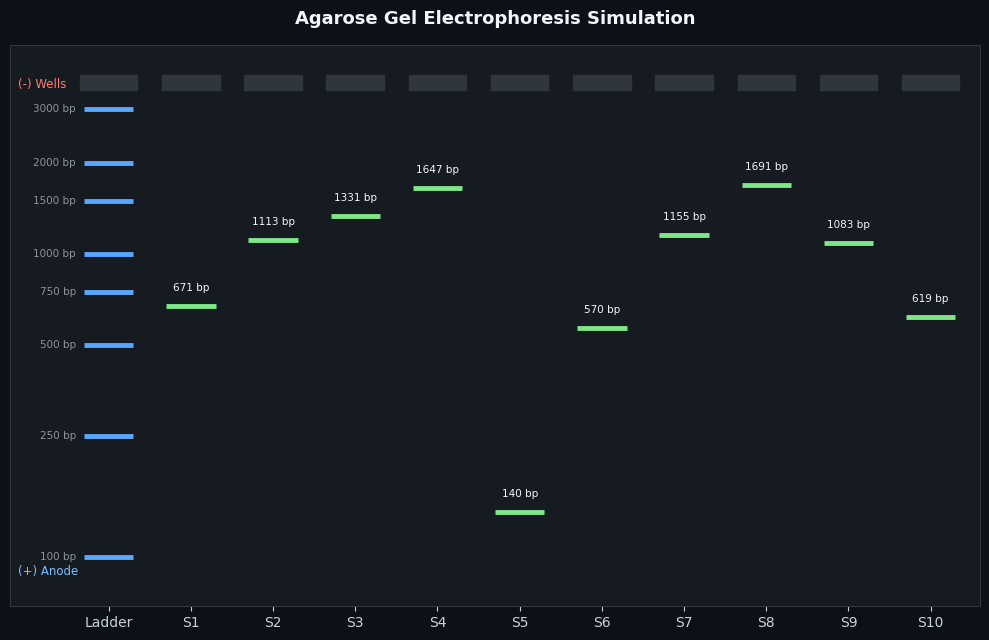

In [23]:

import numpy as np
# 4. Electrophoresis migration model (Logarithmic)
# Smaller fragments experience less friction and travel further down.
def calculate_migration(bp, min_bp=100, max_bp=3000):
    log_min = np.log10(min_bp)
    log_max = np.log10(max_bp)
    # Returns relative migration from 0.05 (near wells) to 0.95 (bottom)
    return 0.05 + 0.90 * (log_max - np.log10(bp)) / (log_max - log_min)

# Standard Ladder sizes matching the board's drawing (500, 1500, 3000 bp, etc.)
ladder_sizes = [3000, 2000, 1500, 1000, 750, 500, 250, 100]
ladder_positions = [calculate_migration(bp) for bp in ladder_sizes]
sample_positions = [calculate_migration(bp) for bp in fragment_sizes]

#Visual Representation
fig, ax = plt.subplots(figsize=(10, 6.5))

ax.set_facecolor("#161b22")
fig.patch.set_facecolor("#0d1117")

# Draw loading wells at the top (Cathode / -)
for lane in range(11):
    ax.add_patch(plt.Rectangle((lane - 0.35, -0.02), 0.7, 0.03, color="#30363d"))

# Draw Ladder in Lane 0
for pos, bp in zip(ladder_positions, ladder_sizes):
    ax.hlines(y=pos, xmin=-0.3, xmax=0.3, color="#58a6ff", linewidth=3.5)
    ax.text(-0.4, pos, f"{bp} bp", color="#8b949e", fontsize=7.5, va="center", ha="right")

# Draw Samples in Lanes 1 to 10
for lane_idx, (pos, bp) in enumerate(zip(sample_positions, fragment_sizes), start=1):
    ax.hlines(y=pos, xmin=lane_idx - 0.3, xmax=lane_idx + 0.3, color="#7ee787", linewidth=3.5)
    ax.text(lane_idx, pos - 0.03, f"{bp} bp", color="#f0f6fc", fontsize=7.5, ha="center")

ax.set_title("Agarose Gel Electrophoresis Simulation", color="#f0f6fc", fontsize=13, weight="bold", pad=15)
ax.set_xticks(range(11))
ax.set_xticklabels(["Ladder"] + [f"S{i}" for i in range(1, 11)], color="#c9d1d9")
ax.tick_params(colors="#c9d1d9")

# Migration orientation (Wells at top, anode at bottom)
ax.set_xlim(-1.2, 10.6)
ax.set_ylim(1.05, -0.08)
ax.set_yticks([])  # Hide arbitrary numeric ticks since the ladder provides the scale

# Cathode/Anode indicators
ax.text(-1.1, 0.0, "(-) Wells", color="#ff7b72", fontsize=8.5, va="center")
ax.text(-1.1, 0.98, "(+) Anode", color="#79c0ff", fontsize=8.5, va="center")

for spine in ax.spines.values():
    spine.set_color("#30363d")

plt.tight_layout()
plt.show()

"Take an arbitrary DNA sequence from the NCBI (National Center for Biotechnology), between 1000 and 3000 nucleotides (letters). Implement a soft. application that detects repetitions between 6 letters and 100 letters in the DNA seq. These repetitions must be produced by a brute force engine and they must be combinations between 3 and 6 letters."

# 2.Brute-Force Engine for Combinations & Repetitions


In [16]:
import itertools

def find_repetitions(seq, min_rep_len=6, max_rep_len=100, min_motif=3, max_motif=6):
    """
    Brute-forces repetitive patterns made of 3-6 letter motifs
    with overall length between 6 and 100 letters
    """
    found_repetitions = {}

    # Brute-force all distinct motif patterns of lengths 3, 4, 5, 6 present in seq
    candidate_motifs = set()
    for m_len in range(min_motif, max_motif + 1):
        for i in range(len(seq) - m_len + 1):
            candidate_motifs.add(seq[i : i + m_len])

    # Test repeated patterns for each candidate motif
    for motif in candidate_motifs:
        m_len = len(motif)

        # Start repeats such that total length >= min_rep_len (at least 2 repeats)
        min_repeats = max(2, (min_rep_len + m_len - 1) // m_len)
        max_repeats = max_rep_len // m_len

        for k in range(min_repeats, max_repeats + 1):
            pattern = motif * k
            pat_len = len(pattern)

            #search for occurrences
            start = 0
            positions = []
            while True:
                idx = seq.find(pattern, start)
                if idx == -1:
                    break
                positions.append(idx)
                start = idx + 1

            if positions:
                found_repetitions[pattern] = {
                    "motif": motif,
                    "motif_length": m_len,
                    "repeats": k,
                    "total_length": pat_len,
                    "count": len(positions),
                    "positions": positions
                }

    return found_repetitions


# 3. Run and Display Results

In [15]:

results = find_repetitions(dna_sequence)

# Sort results by total repeated length descending, then by motif length
sorted_results = sorted(
    results.values(),
    key=lambda x: (x["total_length"], x["count"]),
    reverse=True
)

print(f"Total unique repetitive patterns detected: {len(sorted_results)}\n")
print(f"{'Motif':<10} | {'Repeats':<8} | {'Total Length':<13} | {'Occurrences':<12} | Positions")
print("-" * 65)

for item in sorted_results[:25]:  # Display top 25 longest repetitions
    pos_str = ", ".join(map(str, item["positions"][:5]))
    if len(item["positions"]) > 5:
        pos_str += ", ..."
    print(
        f"{item['motif']:<10} | {item['repeats']:<8} | "
        f"{item['total_length']:<13} | {item['count']:<12} | {pos_str}"
    )

Total unique repetitive patterns detected: 50

Motif      | Repeats  | Total Length  | Occurrences  | Positions
-----------------------------------------------------------------
GGCAGG     | 2        | 12            | 1            | 421
CACCAT     | 2        | 12            | 1            | 218
CGCTG      | 2        | 10            | 1            | 692
CGC        | 3        | 9             | 1            | 569
TTT        | 3        | 9             | 1            | 301
ACC        | 3        | 9             | 1            | 213
GCC        | 3        | 9             | 1            | 570
CCA        | 3        | 9             | 1            | 214
GCTG       | 2        | 8             | 2            | 974, 1801
TTTT       | 2        | 8             | 2            | 301, 302
CCAG       | 2        | 8             | 1            | 2002
ACAG       | 2        | 8             | 1            | 154
ACCA       | 2        | 8             | 1            | 465
GGAC       | 2        | 8             | 1  